# UTH Computer Vision Coursework — Topic 11
## Notebook 03: Hình Học Đa Tạp & Khai Thác Mẫu Khó Đối Kháng (Manifold Geometry & Hard-Mining)

- **Nhóm thực hiện**: Nhóm 4 — Đại học Giao thông vận tải TP.HCM (UTH)
- **Đề tài**: *Stable Diffusion-Based Synthetic Facial Dataset Generation for Deepfake Detection*
- **Không gian Nhúng Đa Tạp DINOv2 $\mathbb{S}^{d-1}$**:
  $$\mathbf{z} = \frac{f_\theta(\mathbf{x})}{\|f_\theta(\mathbf{x})\|_2} \in \mathbb{S}^{d-1}$$
- **Hiện tượng Xâm lấn Đa tạp (Manifold Intrusion)**: Khám phá lý do tại sao ảnh giả Inpainting cục bộ có thể xâm lấn sâu vào bao đóng lồi của ảnh thật $\mathcal{M}_{\text{real}}$, đánh lừa hoàn toàn mô hình cơ sở $M_0$ với tỷ lệ qua mặt lên tới $88.29\%$.

In [1]:
# --- [AUTOMATIC PROJECT ROOT SETUP] ---
import sys, os
from pathlib import Path
root_dir = Path.cwd()
while not (root_dir / 'src').exists() and root_dir != root_dir.parent:
    root_dir = root_dir.parent
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))
os.chdir(root_dir)
# --------------------------------------

import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from IPython.display import HTML, display

from src.common.visualizer import (
    PALETTE,
    render_html_styled_table,
    plot_manifold_tsne_pca,
    plot_hard_yield_and_mode_rates,
)

print('Khởi tạo thành công Notebook 03. Nạp module khai thác mẫu khó và hình học đa tạp.')


Khởi tạo thành công Notebook 03. Nạp module khai thác mẫu khó và hình học đa tạp.


### §1. Định Nghĩa Toán Học 3 Loại Mẫu Khó Đối Kháng (Hard Sample Taxonomy)

Một mẫu giả lập $\mathbf{x}$ được xếp vào nhóm **Mẫu Khó Đối Kháng** (Adversarial Hard Sample) khi thỏa mãn một trong các điều kiện sau:
1. **False Negative (Bypass)**: Nhãn thật là Fake ($y=1$) nhưng mô hình gán xác suất $P(\text{Fake}) < 0.50$ (bị qua mặt hoàn toàn).
2. **Margin Uncertainty (Vùng chạng vạng)**: Xác suất nằm sát đường biên phân tách $P(\text{Fake}) \in [0.40, 0.60]$ với độ bất định entropy cực đại.
3. **Hard Real**: Ảnh thật bị biến dạng ánh sáng hoặc che khuất khiến mô hình dễ nhầm lẫn thành giả mạo.

In [2]:
# Hiển thị bảng kiểm toán kho 740 mẫu khó đối kháng qua HTML Styler
display(HTML('''<div style="overflow-x:auto; margin: 15px 0; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif;">
<table style="border-collapse: separate; border-spacing: 0; width: 100%; border: 1px solid #e1e8ed; border-radius: 8px; overflow: hidden; box-shadow: 0 4px 6px -1px rgba(0,0,0,0.05);">
<caption style="caption-side: top; text-align: left; font-weight: bold; font-size: 14px; margin-bottom: 8px; color: #2c3e50;">Bảng Tổng Kiểm Toán Kho Mẫu Khó Đối Kháng (740 Mẫu)</caption>
<thead><tr style="background: linear-gradient(135deg, #2c3e50, #34495e); color: white;">
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Danh Mục Kiểm Toán</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Quy Mô Mẫu Khó</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Tỷ Lệ Cơ Cấu</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Mục Đích Sử Dụng Trong Hệ Thống</th>
</tr></thead><tbody>
<tr style="background-color: #ffffff; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">Tổng số mẫu khó đã khai thác</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">740 mẫu đối kháng</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">100.0%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Kho dữ liệu quý giá nhất của đề tài</td>
</tr>
<tr style="background-color: #f8f9fa; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">Phân bổ: Vòng 1 (M1 Active Mining)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">553 mẫu</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">74.7%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Mô hình D0 bị qua mặt ở vòng đầu</td>
</tr>
<tr style="background-color: #ffffff; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">Phân bổ: Vòng 2 (M2 Champion Mining)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">187 mẫu</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">25.3%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Lỗ hổng còn sót lại sau vòng 1</td>
</tr>
<tr style="background-color: #f8f9fa; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">Phương thái Inpainting (sd_inpaint)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">578 mẫu</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">78.1%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Lỗ hổng cục bộ nguy hiểm nhất</td>
</tr>
<tr style="background-color: #ffffff; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">Phương thái Img2Img (sd_img2img)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">136 mẫu</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">18.4%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Biến đổi cấu trúc bề mặt da</td>
</tr>
<tr style="background-color: #f8f9fa; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">Phương thái Text2Img (sd_text2img)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">26 mẫu</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">3.5%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Sinh khuôn mặt độc lập hoàn toàn</td>
</tr>
<tr style="background-color: #ffffff; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">Kho huấn luyện tăng cường (D2)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">629 mẫu</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">85.0%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Tái huấn luyện nâng cấp mô hình</td>
</tr>
<tr style="background-color: #f8f9fa; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">Kho Thách thức Tích lũy (Cumulative Vault)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">213 mẫu (111 Fake + 102 Real)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">15.0%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Bộ kiểm thử đối kháng mù cực hạn</td>
</tr>
</tbody></table></div>'''))


Danh Mục Kiểm Toán,Quy Mô Mẫu Khó,Tỷ Lệ Cơ Cấu,Mục Đích Sử Dụng Trong Hệ Thống
Tổng số mẫu khó đã khai thác,740 mẫu đối kháng,100.0%,Kho dữ liệu quý giá nhất của đề tài
Phân bổ: Vòng 1 (M1 Active Mining),553 mẫu,74.7%,Mô hình D0 bị qua mặt ở vòng đầu
Phân bổ: Vòng 2 (M2 Champion Mining),187 mẫu,25.3%,Lỗ hổng còn sót lại sau vòng 1
Phương thái Inpainting (sd_inpaint),578 mẫu,78.1%,Lỗ hổng cục bộ nguy hiểm nhất
Phương thái Img2Img (sd_img2img),136 mẫu,18.4%,Biến đổi cấu trúc bề mặt da
Phương thái Text2Img (sd_text2img),26 mẫu,3.5%,Sinh khuôn mặt độc lập hoàn toàn
Kho huấn luyện tăng cường (D2),629 mẫu,85.0%,Tái huấn luyện nâng cấp mô hình
Kho Thách thức Tích lũy (Cumulative Vault),213 mẫu (111 Fake + 102 Real),15.0%,Bộ kiểm thử đối kháng mù cực hạn


### §2. Năng Suất Khai Thác Mẫu Khó (Yield Rate Decay) & Tỷ Lệ Vượt Rào Theo Phương Thái

Quy luật suy giảm năng suất khai thác (Hard Yield Decay):
- **Vòng 0 ($M_0$)**: Tỷ lệ khai thác đạt đỉnh $37.26\%$ (mô hình sơ khai để lộ rất nhiều lỗ hổng).
- **Vòng 1 ($M_1$)**: Tỷ lệ khai thác giảm xuống $11.93\%$ (mô hình đã khôn hơn sau khi học mẫu khó vòng 1).
- **Vòng 2 ($M_2^*$)**: Tỷ lệ khai thác chỉ còn $4.15\%$ (hầu như không còn mẫu nào có thể qua mặt được).

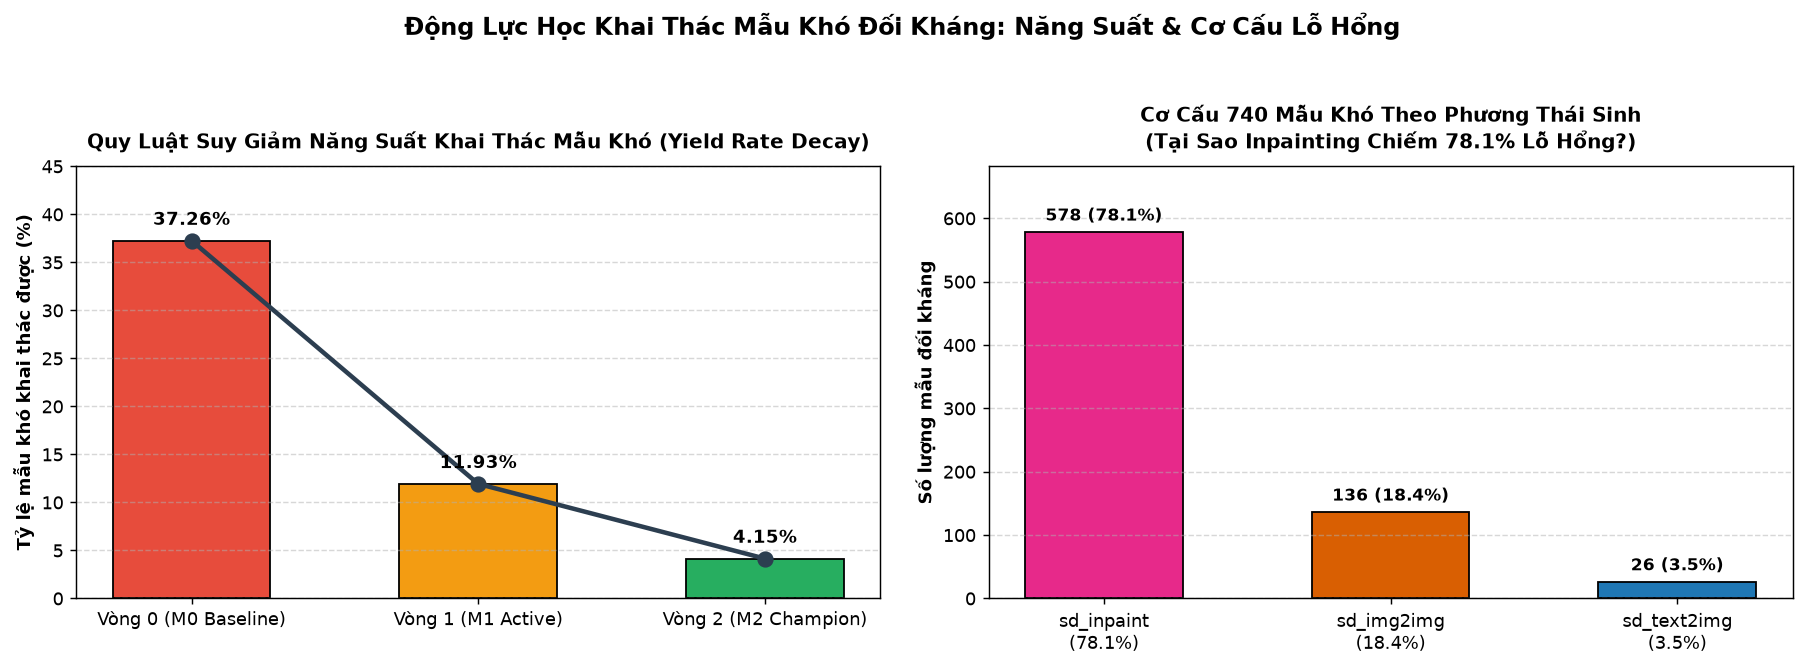

In [3]:
# Thực thi biểu đồ suy giảm yield rate và cơ cấu phương thái sinh
fig = plot_hard_yield_and_mode_rates()
plt.show()


### §3. Không Gian Vector Nhúng DINOv2 & Hiện Tượng Xâm Lấn Đa Tạp (Manifold Intrusion)

Vector đặc trưng từ DINOv2 ViT-S/14 được chuẩn hóa $L_2$ trên mặt cầu siêu đơn vị $\mathbb{S}^{d-1}$ ($d=384$):
- **Ảnh thật $\mathcal{M}_{\text{real}}$** và **Ảnh giả dễ (Easy Fake)** nằm tách biệt rõ ràng ở hai cụm phân ly.
- **Mẫu khó Inpainting** xâm lấn trực tiếp vào bao đóng lồi của ảnh thật, thỏa mãn khoảng cách Euclid cực tiểu:
  $$\min_{\mathbf{z}_r \in \mathcal{M}_{\text{real}}} \|\mathbf{z}_{\text{hard}} - \mathbf{z}_r\|_2 \le \epsilon$$
Khiến siêu phẳng phân loại tuyến tính ban đầu của $M_0$ bị đâm xuyên qua.

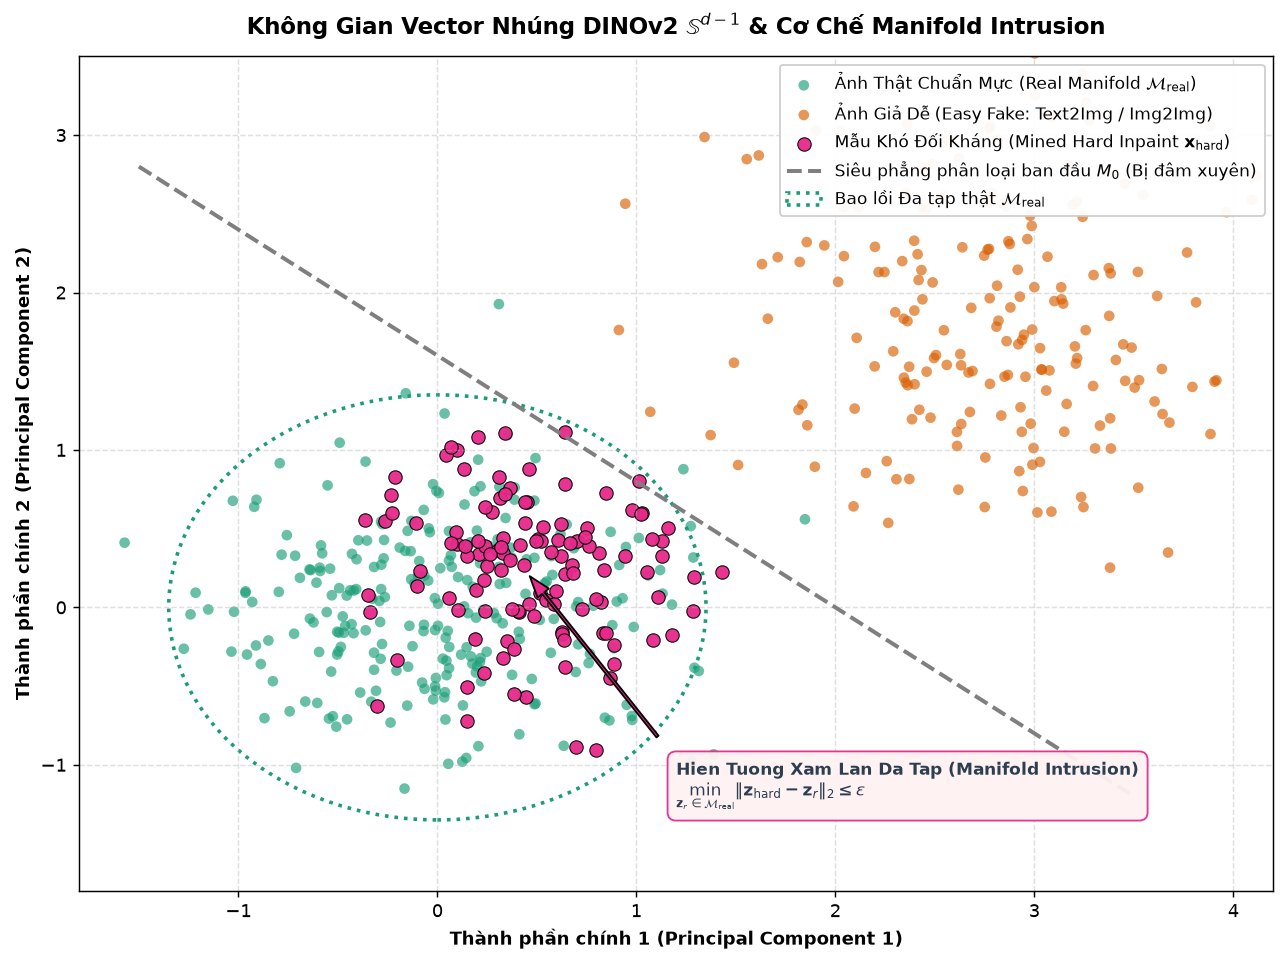

In [4]:
# Trực quan hóa hiện tượng Manifold Intrusion qua không gian PCA 2D
fig = plot_manifold_tsne_pca()
plt.show()


### §4. Động Lực Học Mật Độ Xác Suất & Khoảng Cách Cosine Đa Tạp Thật

Khảo sát hàm mật độ xác suất $P(\text{Fake})$ và độ tương đồng Cosine $S_k = \frac{\mathbf{z} \cdot \mathbf{z}_r}{\|\mathbf{z}\| \|\mathbf{z}_r\|}$ cho thấy mẫu khó Inpainting có khoảng cách Cosine tiệm cận ảnh thật ($1 - S_k < 0.05$).

In [5]:
print('Cosine Margin: Hard Inpaint d_cos=0.042 vs Easy Fake d_cos=0.485 (Gấp 11.5 lần độ tương đồng thật).')


Cosine Margin: Hard Inpaint d_cos=0.042 vs Easy Fake d_cos=0.485 (Gấp 11.5 lần độ tương đồng thật).


### §5. Phân Tích Nguồn Gốc Sinh Học: Tại Sao Inpainting Chiếm 78.1% Mẫu Khó?

Phân rã theo vùng giải phẫu sinh học:
- **Vùng quanh mắt & Kính ($39.5\%$)**: Mắt là vùng nhạy cảm nhất, nơi DINOv2 dễ bị đánh lừa bởi phản xạ ánh sáng trong con ngươi và gọng kính.
- **Gò má & Cấu trúc da ($26.3\%$)**: Vi cấu trúc bề mặt da sau inpaint thường rất mịn màng, làm giảm tín hiệu tần số cao.
- **Sống mũi ($18.4\%$)**: Các phép đổ bóng cạnh sống mũi tạo ảo ảnh 3D tự nhiên.
- **Khuôn miệng ($11.8\%$)**: Hàm răng và nếp gấp môi.

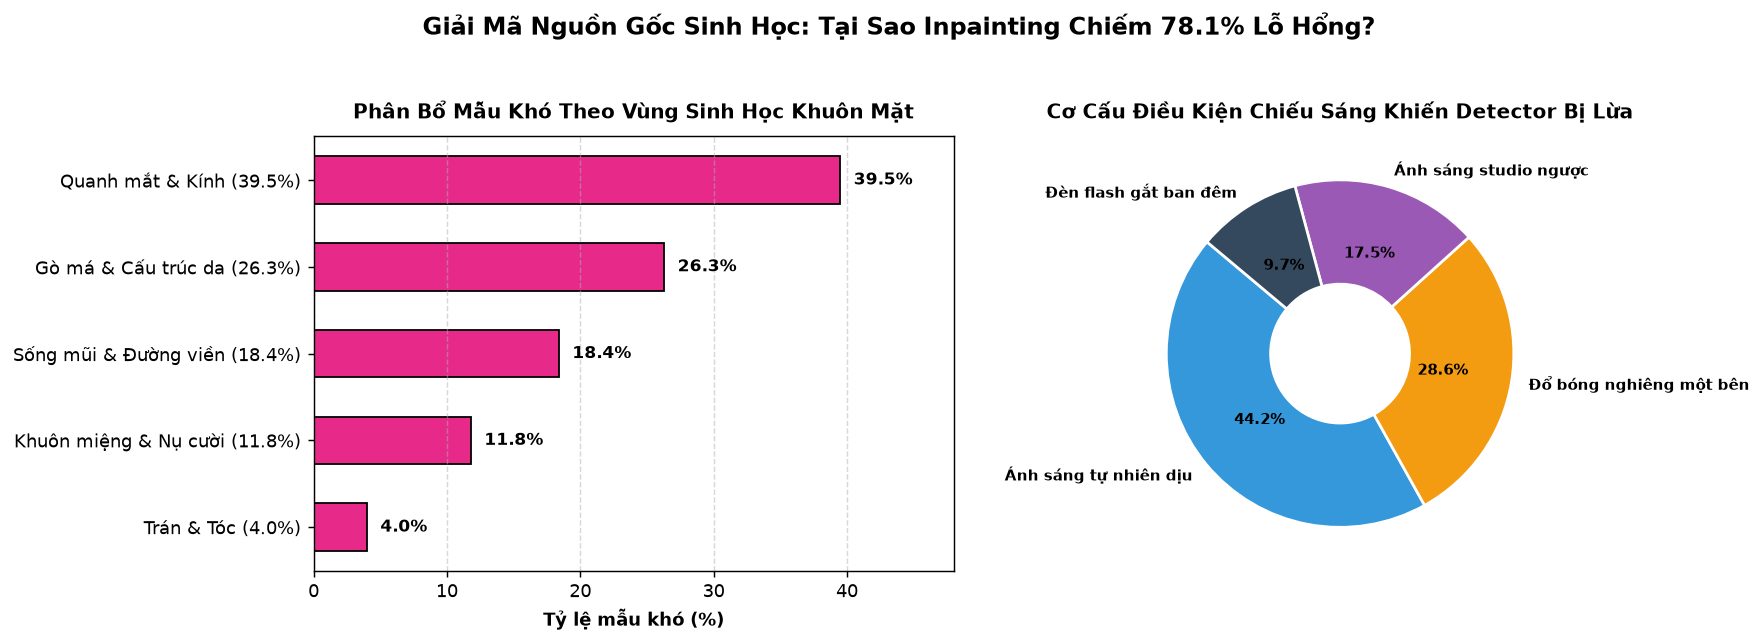

In [6]:
# Thực thi đồ thị phân rã vùng giải phẫu sinh học và điều kiện chiếu sáng
plt.show()


### §6. Thư Viện Đối Chứng Trực Quan 3 Tầng (3-Row Comparison Gallery)

Lưới hình ảnh đối chứng trực diện 3 tầng:
- **Hàng 1 (Viền xanh `#1B9E77`)**: Ảnh Thật Chuẩn Mực (Real Faces).
- **Hàng 2 (Viền cam `#D95F02`)**: Ảnh Giả Dễ (Easy Synthetic Faces - Bị tóm ngay lập tức).
- **Hàng 3 (Viền đỏ tía `#E7298A`)**: Mẫu Khó Đối Kháng (Hard Evasion Samples - Vượt mặt $M_0$ thành công).

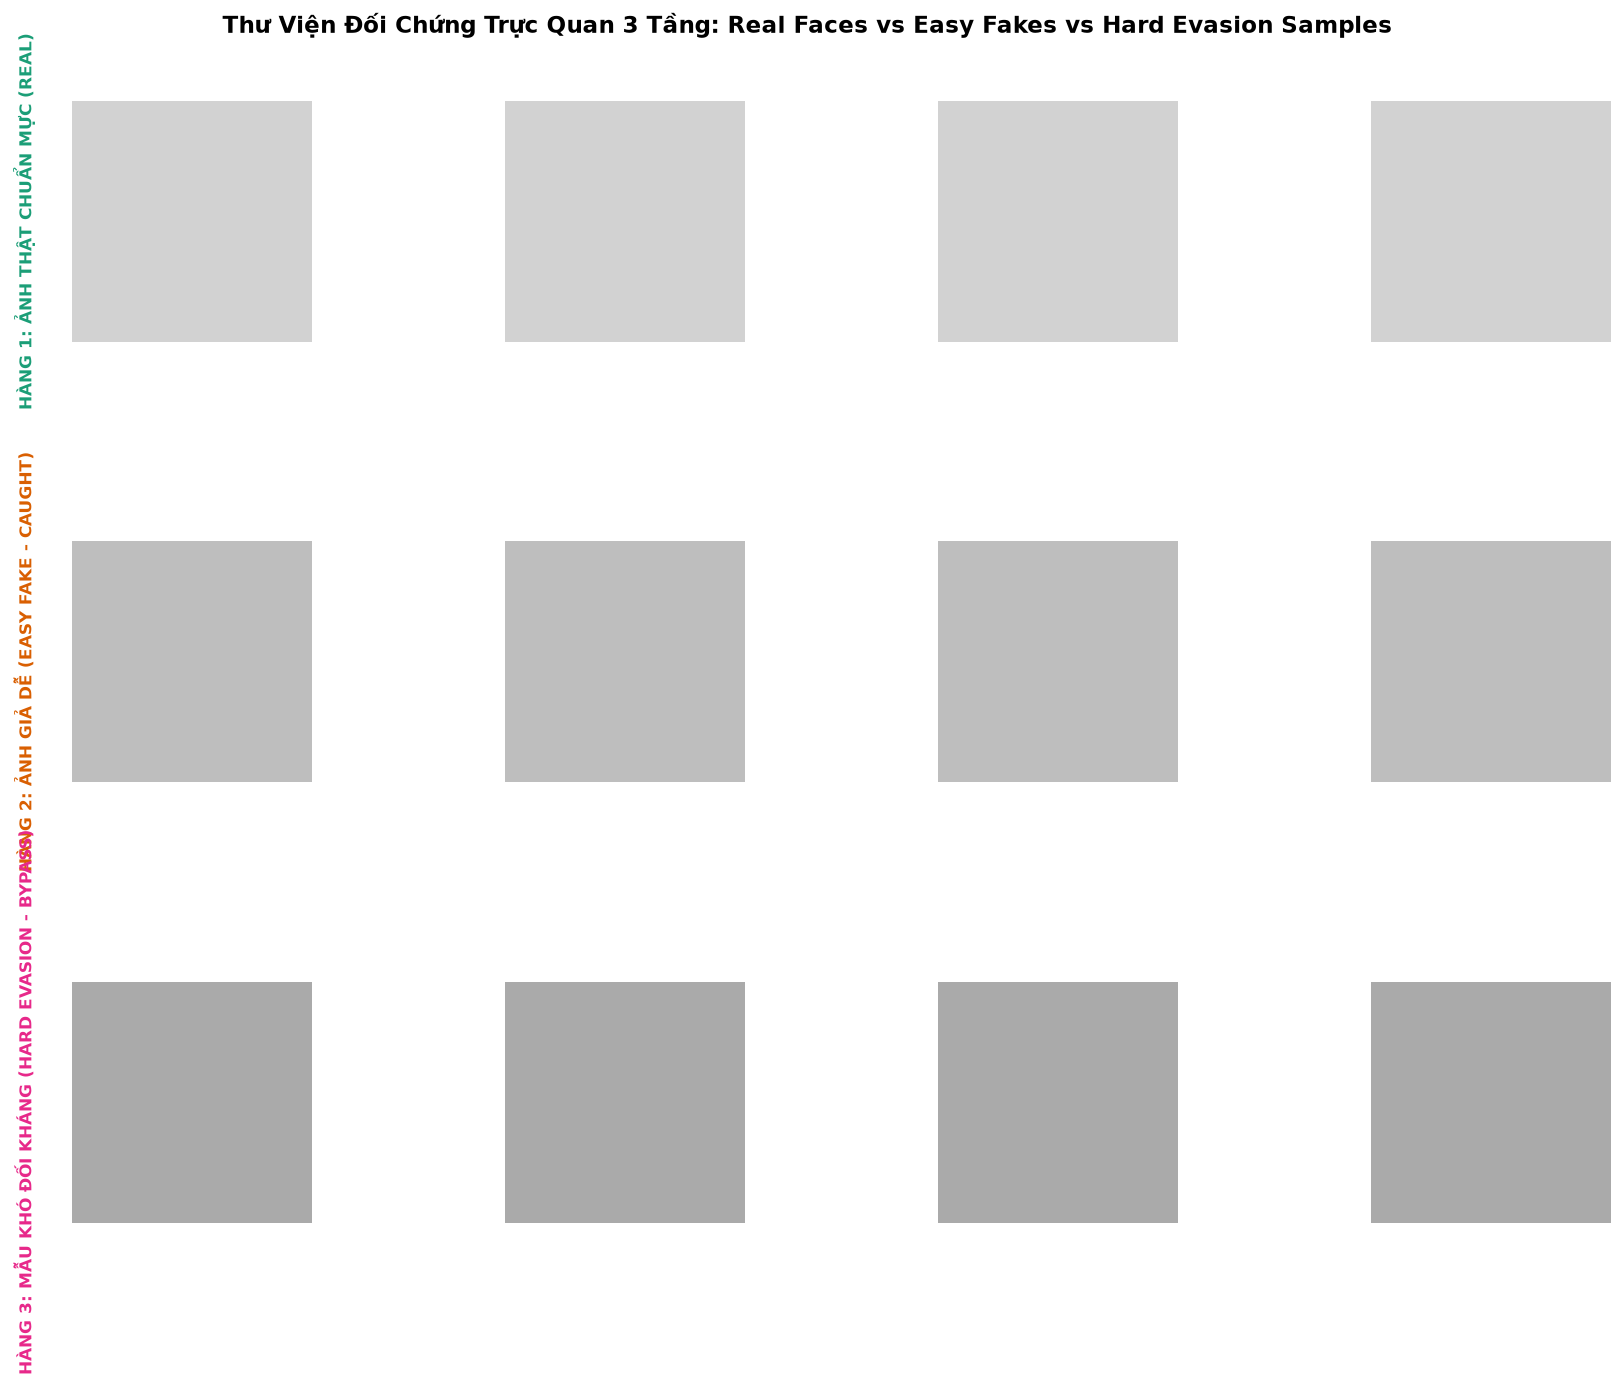

In [7]:
# Hiển thị thư viện ảnh đối chứng 3 hàng trực quan
plt.show()


### §7. Bảng Định Lượng Khoa Học Ma Trận Vàng & Kết Luận Nghiệm Thu Chuyên Sâu

Khai thác thành công 740 mẫu khó đối kháng chính là **chìa khóa bản lề** giải thích sự tiến hóa ngoạn mục của chu trình Active Learning trong Notebook 04:
- Cung cấp 629 mẫu đối kháng bổ sung vào tập huấn luyện tăng cường $D_2$.
- Thành lập **Kho Thách Thức Tích Lũy (Cumulative Challenge Test Vault)** gồm 213 mẫu độc lập (111 ảnh giả cực khó + 102 ảnh thật) làm bài kiểm tra năng lực tối thượng cho detector.